# 05 — Règles d'association (Apriori)

**Rôle :** extraire des règles lisibles « *si* conditions *alors* classe » (chapitre 5 du cours) qui décrivent
des signatures d'intrusion. Implémentation d'Apriori : `src/unsupervised/association.py`.

1. **Discrétisation** : chaque variable numérique est découpée en terciles (bas / moyen / élevé) ; les
   catégorielles gardent leurs 6 modalités principales.
2. **Itemsets fréquents** : niveau par niveau ; un candidat de taille k n'est compté que si tous ses
   sous-ensembles de taille k−1 sont fréquents (**anti-monotonie** du support).
3. **Règles** X ⇒ Y avec support, confiance, lift, levier et conviction.

In [1]:
# Configuration : le notebook s'exécute depuis notebooks/, on ajoute la racine du dépôt au chemin
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from src import config as C
from src import visualization as V
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 200)
print('Racine du projet :', ROOT.name)

Racine du projet : Network-Intrusion-Detection-System


In [2]:
from src.unsupervised import association as AR
train = pd.read_csv(C.TRAIN_FILE, low_memory=False)
tr = AR.discretize(train.sample(6000, random_state=1))
print('Exemple de transaction :', sorted(tr[0]))
import time; t = time.time()
freq = AR.apriori(tr, min_support=0.05, max_len=4)
print(f"{len(freq)} itemsets fréquents (support ≥ 5 %) en {time.time() - t:.1f}s")
print(pd.Series({k: sum(1 for s in freq if len(s) == k) for k in range(1, 5)}, name="nombre d'itemsets par taille"))

Exemple de transaction : ['classe=Normal', 'ct_dst_src_ltm=bas', 'ct_srv_src=bas', 'dbytes=élevé', 'dmeansz=élevé', 'dttl=bas', 'dur=moyen', 'proto=tcp', 'sbytes=élevé', 'service=-', 'sload=élevé', 'smeansz=moyen', 'spkts=élevé', 'state=fin', 'sttl=bas']


12111 itemsets fréquents (support ≥ 5 %) en 12.8s
1      43
2     682
3    3423
4    7963
Name: nombre d'itemsets par taille, dtype: int64


In [3]:
rules = AR.association_rules(freq, min_confidence=0.9, consequent_prefix='classe=')
print(len(rules), 'règles vers la classe (confiance ≥ 90 %)')
display(rules.head(15).round(4))

1701 règles vers la classe (confiance ≥ 90 %)


,antecedent,consequent,support,confidence,lift,leverage,conviction,length
0,ct_srv_src=élevé ∧ proto=udp ∧ smeansz=bas,classe=Attaque,0.0547,1.0,2.6714,0.0342,inf,4
1,ct_srv_src=élevé ∧ smeansz=bas ∧ state=int,classe=Attaque,0.0547,1.0,2.6714,0.0342,inf,4
2,service=dns ∧ smeansz=bas,classe=Attaque,0.0543,1.0,2.6714,0.0340,inf,3
3,dmeansz=bas ∧ service=dns ∧ smeansz=bas,classe=Attaque,0.0542,1.0,2.6714,0.0339,inf,4
4,service=dns ∧ smeansz=bas ∧ spkts=bas,classe=Attaque,0.0542,1.0,2.6714,0.0339,inf,4
5,proto=udp ∧ service=dns ∧ smeansz=bas,classe=Attaque,0.0542,1.0,2.6714,0.0339,inf,4
6,sbytes=bas ∧ service=dns ∧ smeansz=bas,classe=Attaque,0.0542,1.0,2.6714,0.0339,inf,4
7,service=dns ∧ smeansz=bas ∧ sttl=élevé,classe=Attaque,0.0540,1.0,2.6714,0.0338,inf,4
8,dbytes=bas ∧ service=dns ∧ smeansz=bas,classe=Attaque,0.0540,1.0,2.6714,0.0338,inf,4
9,dttl=bas ∧ service=dns ∧ smeansz=bas,classe=Attaque,0.0540,1.0,2.6714,0.0338,inf,4


## Règles vers les catégories d'attaque (calculées sur 12 000 attaques par `src.run_unsupervised`)

,antecedent,consequent,support,confidence,lift,leverage,conviction,length
0,ct_srv_src=élevé ∧ service=dns ∧ smeansz=bas,classe=Generic,0.1198,1.0000,6.5898,0.1016,inf,4
1,ct_dst_src_ltm=élevé ∧ service=dns ∧ smeansz=bas,classe=Generic,0.1174,1.0000,6.5898,0.0996,inf,4
2,dur=bas ∧ service=dns ∧ smeansz=bas,classe=Generic,0.0938,1.0000,6.5898,0.0795,inf,4
3,ct_srv_src=élevé ∧ service=dns ∧ sload=moyen,classe=Generic,0.0792,1.0000,6.5898,0.0672,inf,4
4,ct_dst_src_ltm=élevé ∧ service=dns ∧ sload=moyen,classe=Generic,0.0776,1.0000,6.5898,0.0658,inf,4
5,service=dns ∧ sload=élevé ∧ smeansz=bas,classe=Generic,0.0540,1.0000,6.5898,0.0458,inf,4
6,ct_dst_src_ltm=élevé ∧ service=dns ∧ spkts=bas,classe=Generic,0.1013,0.9992,6.5844,0.0859,1031.4720,4
7,service=dns ∧ smeansz=bas ∧ state=int,classe=Generic,0.1213,0.9986,6.5807,0.1029,618.3743,4
8,dttl=0 ∧ service=dns ∧ smeansz=bas,classe=Generic,0.1213,0.9986,6.5807,0.1029,618.3743,4
9,service=dns ∧ smeansz=bas ∧ spkts=bas,classe=Generic,0.1049,0.9984,6.5793,0.0890,534.8216,4


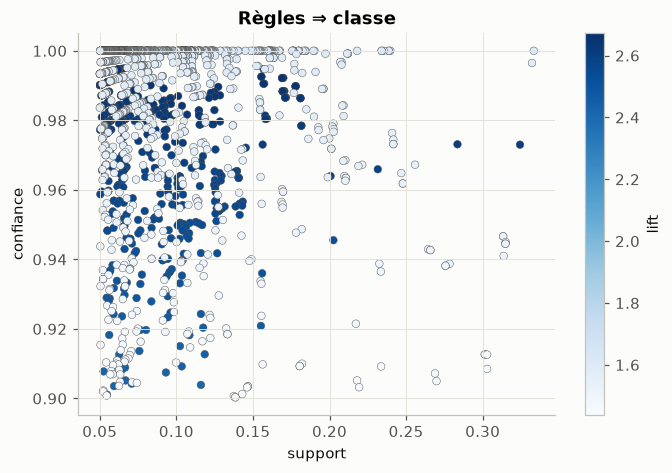

In [4]:
rc = pd.read_csv(C.METRICS_DIR / 'association_rules_category.csv')
display(rc.head(15).round(4))
fig, ax = plt.subplots(figsize=(7, 4.5))
sc = ax.scatter(rules.support, rules.confidence, c=rules.lift, cmap=V.SEQ_CMAP, s=25, edgecolor='#52514e', linewidth=0.3)
plt.colorbar(sc, label='lift'); ax.set_xlabel('support'); ax.set_ylabel('confiance'); ax.set_title('Règles ⇒ classe')
V.save(fig, '05_association_rules'); plt.show()

**Lecture :** les règles de plus fort lift confirment l'EDA : `sttl=élevé ∧ dttl=bas ⇒ Attaque`,
`service=dns ∧ dbytes=bas ∧ ct_srv_src=élevé ⇒ Generic` (rafales DNS unidirectionnelles), `state=fin ∧ sttl=bas ⇒ Normal`.
Contrairement à un arbre, chaque règle est évaluée indépendamment : elles servent d'explications
globales, pas de classifieur complet.